# A tour of MEDT

**Multipartite Entanglement Detection Toolkit**

[Entanglement](https://en.wikipedia.org/wiki/Quantum_entanglement) shared by three or more parties is a resource for quantum networks, sensing and error correction, and it is also a fingerprint of quantum phases of matter. But given a noisy, mixed state, it is hard to tell whether it is entangled at all: the set of unentangled (separable) states has no simple description, and deciding membership is NP-hard in general ([Gurvits 2003](https://arxiv.org/abs/quant-ph/0303055)). In practice one attacks the question from both sides:

- **certificates of entanglement**, such as entanglement witnesses and [semidefinite programs](https://en.wikipedia.org/wiki/Semidefinite_programming) built on the partial transpose, which prove that a state *is* entangled, and
- **certificates of separability**, such as an explicit decomposition into unentangled pieces, which prove that it *is not*.

When the two sides meet, the question is settled. For a friendly introduction to the subject, see the reviews by [Gühne and Tóth](https://arxiv.org/abs/0811.2803) and by [the Horodeckis](https://arxiv.org/abs/quant-ph/0702225).

This notebook runs four light examples, each taking seconds to a minute on a laptop:

1. Is a noisy three-qubit GHZ state genuinely multipartite entangled? We certify the answer from both sides.
2. How much entanglement is there? Upper and lower bounds on an entanglement measure.
3. Entanglement at a quantum phase transition, in the transverse-field Ising chain.
4. Network entanglement: entanglement that cannot be built from pairwise sources.

An appendix shows the helper behind *entanglement microscopy*: pulling the reduced state of a few sites out of a large many-body state, so that any of the methods above can be applied to it.

Each section links to the paper behind the method; the [README](../README.md) has the full reference list.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse

import medt
from medt.states import ghz, ket_to_dm, w, white_noise

plt.rcParams.update({
    "figure.figsize": (6, 3.4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BLUE = "#2a78d6"
MUTED = "#8a8984"


## 1. Is a noisy GHZ state genuinely multipartite entangled?

Take the three-qubit [GHZ state](https://en.wikipedia.org/wiki/Greenberger%E2%80%93Horne%E2%80%93Zeilinger_state) $|\mathrm{GHZ}\rangle = (|000\rangle + |111\rangle)/\sqrt{2}$ and mix it with white noise, which models a noisy preparation:

$$\rho(p) = (1-p)\,|\mathrm{GHZ}\rangle\langle\mathrm{GHZ}| + p\,\frac{\mathbb{1}}{8}.$$

Split the three qubits $A, B, C$ into two groups, for example $A|BC$. A state is *biseparable* if it can be written as a probabilistic mixture of states that are each unentangled across one such split (the split may differ from term to term). Biseparable states can be made by entangling only some of the parties at a time. A state that is not biseparable has **genuine multipartite entanglement** (GME): all three qubits are entangled together.

The **genuine multiparticle negativity** (GMN) of [Jungnitsch, Moroder and Gühne (2011)](https://arxiv.org/abs/1010.6049) is a semidefinite program that tests GME using the [partial transpose](https://en.wikipedia.org/wiki/Peres%E2%80%93Horodecki_criterion); GMN $> 0$ certifies GME.

For this state the exact answer is known: it is GME exactly when $p < 4/7$, i.e. when its overlap with the GHZ state, $(1-p) + p/8$, exceeds $1/2$ ([Gühne and Seevinck 2010](https://arxiv.org/abs/0905.1349)). Let's see GMN find this threshold.

33 SDPs in 1.5 s


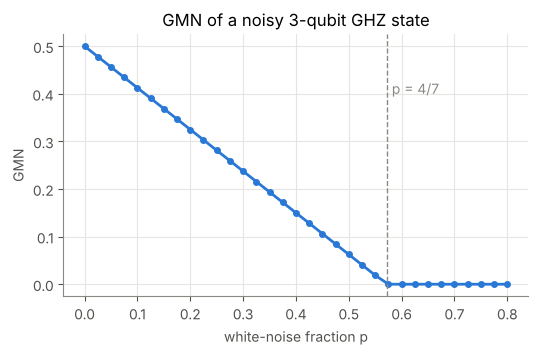

In [2]:
ps = np.linspace(0, 0.8, 33)
rho_ghz = ket_to_dm(ghz(3))
t0 = time.time()
gmn_values = [medt.gmn(white_noise(rho_ghz, p)) for p in ps]
print(f"{len(ps)} SDPs in {time.time() - t0:.1f} s")

fig, ax = plt.subplots()
ax.plot(ps, gmn_values, color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(4 / 7, color=MUTED, ls="--", lw=1)
ax.text(4 / 7 + 0.01, 0.4, "p = 4/7", color=MUTED)
ax.set(xlabel="white-noise fraction p", ylabel="GMN", title="GMN of a noisy 3-qubit GHZ state")
plt.show()


GMN is positive up to $p = 4/7$ and vanishes beyond it. A vanishing GMN alone does not prove that the state is biseparable, since GMN is only a sufficient test for entanglement. The **adaptive polytope** method of [Ohst, Yu, Gühne and Sarbicki (2024)](https://arxiv.org/abs/2210.10054) provides the other side: it searches for an explicit biseparable decomposition, and reports a robustness $t \ge 1$ when it finds one.

In [3]:
for p in (0.5, 0.65):
    res = medt.polytope_biseparable(white_noise(rho_ghz, p), [2, 2, 2], seed=0)
    print(f"p = {p}: biseparable certified = {res.certified}  (robustness t = {res.robustness:.3f})")


p = 0.5: biseparable certified = False  (robustness t = 0.853)


p = 0.65: biseparable certified = True  (robustness t = 1.145)


At $p = 0.65$ the state is certified biseparable, and at $p = 0.5$ GMN certified it GME. Together the two methods pin down the threshold.

## 2. How much entanglement is there?

Beyond a yes/no answer, one often wants to *quantify* entanglement. The **genuine multipartite concurrence** (GMC) of [Ma *et al.* (2011)](https://arxiv.org/abs/1101.2001) is one such measure. For pure states it has a closed form; for mixed states it is a *convex roof*, the minimum average over all ways of writing $\rho$ as a mixture of pure states. That minimum is hard to compute exactly, so MEDT brackets it:

- `gmc_lower_bound`: a lower bound from [Ma *et al.* (2011)](https://arxiv.org/abs/1101.2001), optimized over product states.
- `gmc_convex_roof`: an upper bound, found by gradient descent over decompositions, as in [Lyu *et al.* (2025)](https://arxiv.org/abs/2412.12533). Every decomposition of $\rho$ into $k$ pure states corresponds to a $k \times r$ matrix with orthonormal columns ($r$ is the rank of $\rho$). These matrices form a curved space, the [Stiefel manifold](https://en.wikipedia.org/wiki/Stiefel_manifold), so the descent has to stay on it; this is *Riemannian* gradient descent, introduced gently in [Boumal's free textbook](https://sma.epfl.ch/~nboumal/book/IntroOptimManifolds_Boumal_2022.pdf).

Here is a W state $(|001\rangle + |010\rangle + |100\rangle)/\sqrt{3}$ with 10% white noise.

In [4]:
rho_w = white_noise(ket_to_dm(w(3)), 0.1)
lo = medt.gmc_lower_bound(rho_w, [2, 2, 2], n_starts=5, seed=0)
hi = medt.gmc_convex_roof(rho_w, [2, 2, 2], seed=0)
print(f"noisy W state: {lo:.4f} <= GMC <= {hi:.4f}")
print(f"pure W state:  GMC = {medt.gmc_pure(w(3)):.4f}")


noisy W state: 0.4709 <= GMC <= 0.7042
pure W state:  GMC = 0.9428


## 3. Entanglement at a quantum phase transition

The [transverse-field Ising chain](https://en.wikipedia.org/wiki/Transverse-field_Ising_model) $H = -\sum_i (X_i X_{i+1} + h Z_i)$ is the textbook example of a [quantum phase transition](https://en.wikipedia.org/wiki/Quantum_phase_transition): a ferromagnet for $h < 1$, a paramagnet for $h > 1$, and critical at $h = 1$.

The model maps to free fermions, so the reduced density matrix of any few spins of the *infinite* chain can be computed exactly, without diagonalizing a large Hamiltonian ([Fagotti and Essler 2013](https://arxiv.org/abs/1302.6944)). `medt.tfim.tfim_rdm` does this at zero or finite temperature. Below we compute the GMN of three neighbouring spins in the ground state as the field $h$ varies.

/home/claude/entdetect/src/medt/gmn.py:165: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  prob.solve(solver=solver, **solver_kwargs)


30 reduced states + SDPs in 2.8 s


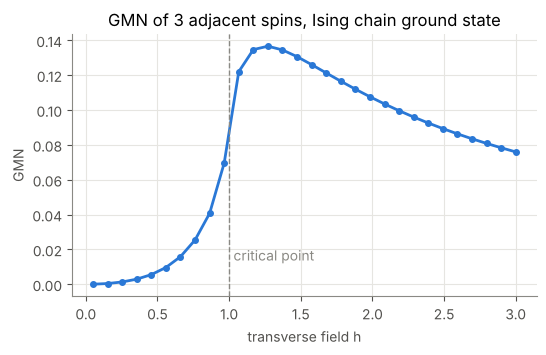

In [5]:
hs = np.linspace(0.05, 3.0, 30)
t0 = time.time()
gmn_tfim = [medt.gmn(medt.tfim.tfim_rdm(h, [0, 1, 2])) for h in hs]
print(f"{len(hs)} reduced states + SDPs in {time.time() - t0:.1f} s")

fig, ax = plt.subplots()
ax.plot(hs, gmn_tfim, color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(1.0, color=MUTED, ls="--", lw=1)
ax.text(1.03, max(gmn_tfim) * 0.1, "critical point", color=MUTED)
ax.set(xlabel="transverse field h", ylabel="GMN", title="GMN of 3 adjacent spins, Ising chain ground state")
plt.show()


The GMN rises sharply near the critical point, peaks just above it, and decays slowly in the paramagnetic phase. At small $h$ the three spins are close to a classical mixture of "all up" and "all down", so GME vanishes. For finite temperature, pass `beta=1/T` to `tfim_rdm`.

Studies of the same chain with other GME criteria see the same picture, with a derivative that diverges at the critical point: [Wang, Song, Lyu, Witczak-Krempa and Meng (2025)](https://arxiv.org/abs/2402.14916) and [Lyu, Song, Wang, Meng and Witczak-Krempa (2025)](https://arxiv.org/abs/2412.12533).

## 4. Network entanglement

Many quantum networks distribute entanglement through *two-party* sources, such as photon pairs, and then let each party act locally. Some multipartite entangled states can be made this way and some cannot. States that cannot have *genuine network multipartite entanglement* (GNME), a stronger property than GME ([Navascués *et al.* 2020](https://arxiv.org/abs/2002.02773)).

The **ring inflation** test certifies GNME. Imagine that the state did come from a network; then copies of its sources could be rewired into a larger ring, and the resulting states would have to exist. A semidefinite program checks whether they can. The test returns the largest $t$ for which the noisier state $t\rho + (1-t)\mathbb{1}/D$ passes, so $t < 1$ certifies GNME. The **Gilbert criterion** gives the other side: a noise level above which the state *is* a network state. Both follow [Lyu, Lauand and Witczak-Krempa (2026)](https://arxiv.org/abs/2512.11118).

In [6]:
for name, psi, p in [("GHZ", ghz(3), 0.2), ("GHZ", ghz(3), 0.45), ("W", w(3), 0.25)]:
    rho = white_noise(ket_to_dm(psi), p)
    t = medt.ring_inflation_robustness(rho, [2, 2, 2])
    verdict = "GNME certified" if t < 1 else "not certified by level-2 inflation"
    print(f"{name} with p = {p}: t_max = {t:.3f} -> {verdict}")


GHZ with p = 0.2: t_max = 0.790 -> GNME certified


GHZ with p = 0.45: t_max = 1.149 -> not certified by level-2 inflation


W with p = 0.25: t_max = 0.933 -> GNME certified


The noisy GHZ state at $p = 0.45$ is still GME (since $0.45 < 4/7$), but level-2 inflation no longer certifies network entanglement. Passing `level=3` gives tighter bounds and reproduces the thresholds $p = 0.3878$ (GHZ) and $p = 0.3486$ (W) of [Lyu, Lauand and Witczak-Krempa (2026)](https://arxiv.org/abs/2512.11118), in a few minutes each.

## Appendix: entanglement microscopy

In [entanglement microscopy](https://arxiv.org/abs/2402.14916) (Wang, Song, Lyu, Witczak-Krempa and Meng, Nat. Commun. 2025), one looks at a quantum many-body system through a microscope: zoom in on a few sites, extract their reduced state, and examine its entanglement. MEDT provides the extraction step as a helper. Once you have the reduced state, every method above applies.

Many-body calculations usually produce one large pure state $|\psi\rangle$ of $N$ spins, for example a ground state. The [reduced density matrix](https://en.wikipedia.org/wiki/Partial_trace) of a few spins is obtained by tracing out the rest. Forming the full $2^N \times 2^N$ density matrix first would be wasteful (for $N = 20$ that is a trillion entries), so MEDT works directly from $|\psi\rangle$:

- `keep_systems(state, keep, dims)` returns the reduced state of the subsystems in `keep`, in the order requested.
- `partial_trace(state, trace_out, dims)` traces out the listed subsystems.

Both accept kets or density matrices, dense or sparse, with any local dimensions. For fermions, `medt.fermions.fermionic_keep_systems` does the same, keeping track of the signs that appear when fermionic modes are reordered.

To get a large state, `medt.tfim.tfim_ground_state` finds the ground state of a ring of 20 Ising spins at the critical point with the [Lanczos algorithm](https://en.wikipedia.org/wiki/Lanczos_algorithm), a vector of $2^{20} \approx 10^6$ amplitudes. A finite periodic chain is again solvable by free fermions, which gives an exact energy to check against.

In [7]:
L, h = 20, 1.0
t0 = time.time()
energy, psi = medt.tfim.tfim_ground_state(L, h)
print(f"Lanczos, L = {L}: E0 = {energy:.8f} in {time.time() - t0:.1f} s")
k = np.pi * (2 * np.arange(L) + 1) / L
print(f"free-fermion exact:  E0 = {-np.sum(np.sqrt(1 + h**2 - 2 * h * np.cos(k))):.8f}")

dims = [2] * L
t0 = time.time()
rho_adj = medt.keep_systems(psi, [0, 1, 2], dims)        # three adjacent spins
rho_far = medt.keep_systems(psi, [10, 0, 5], dims)       # spaced spins, ordered as (10, 0, 5)
rho_pt = medt.partial_trace(psi, range(3, L), dims)      # same as rho_adj, by tracing out the rest
print(f"three reduced states in {time.time() - t0:.2f} s")
print("keep_systems agrees with partial_trace:", np.allclose(rho_adj, rho_pt))

print(f"GMN, 3 adjacent spins, L = 20 ring:     {medt.gmn(rho_adj):.5f}")
print(f"GMN, 3 adjacent spins, infinite chain:  {medt.gmn(medt.tfim.tfim_rdm(h, [0, 1, 2])):.5f}")
print(f"GMN, spins (10, 0, 5):                  {max(medt.gmn(rho_far), 0.0):.5f}")


Lanczos, L = 20: E0 = -25.49098969 in 10.2 s
free-fermion exact:  E0 = -25.49098969
three reduced states in 0.01 s
keep_systems agrees with partial_trace: True
GMN, 3 adjacent spins, L = 20 ring:     0.09405


GMN, 3 adjacent spins, infinite chain:  0.09140
GMN, spins (10, 0, 5):                  0.00000


Through this microscope, three neighbouring spins on a ring of 20 sites already look almost like those of the infinite chain in section 3, while spins five sites apart share no genuine three-party entanglement.

Sparse states are handled without ever building a dense vector. Here are two qubits of a 24-qubit W state, which has only 24 nonzero amplitudes out of $2^{24} \approx 1.7 \times 10^7$:

In [8]:
n = 24
w24 = sparse.coo_array((np.full(n, n**-0.5), (1 << np.arange(n),)), shape=(2**n,))
rho_pair = medt.keep_systems(w24, [3, 17], [2] * n)
print(np.round(rho_pair.real, 4))
print("negativity between the two qubits:", round(medt.negativity(rho_pair, [0], [2, 2]), 5))


[[0.9167 0.     0.     0.    ]
 [0.     0.0417 0.0417 0.    ]
 [0.     0.0417 0.0417 0.    ]
 [0.     0.     0.     0.    ]]
negativity between the two qubits: 0.00189


## Where to go next

- The [README](../README.md) lists every method with a usage snippet and its references.
- The `tests/` folder reproduces published numbers: GMN in the Kitaev honeycomb model, GMN and Rains entanglement in the Ising chain, and network-entanglement thresholds.
- All semidefinite programs go through [CVXPY](https://www.cvxpy.org), so you can pass `solver="MOSEK"` or any other installed solver.